# Triagem de compras públicas

Esta análise de oito materiais de cinco famílias prioriza resultados homologados para conferência documental. Cada preço é comparado com o histórico da mesma apresentação do material. A fila também considera o texto do objeto e a recorrência das compras.

No Colab, selecione **Ambiente de execução → Executar tudo**. A primeira célula carrega os dados da versão utilizada na análise. No Jupyter local, abra o notebook na pasta que contém `dados` e `index.html`. As saídas salvas permitem ler a análise antes de executar o código.

[Painel interativo](https://asmunck.github.io/triagem-compras-publicas/) · [Repositório](https://github.com/asmunck/triagem-compras-publicas) · [Versão dos dados](https://github.com/asmunck/triagem-compras-publicas/tree/1fb584581cb6945bf9f6f398979ca74cc7237588)

In [1]:
import html
import io
import json
import tempfile
import zipfile
from urllib.error import URLError
from urllib.request import urlopen
from pathlib import Path, PurePosixPath

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

def abrir_zip(conteudo):
    """Lê as entradas conhecidas do projeto mesmo quando o ZIP tem uma pasta externa."""
    dest = Path(tempfile.mkdtemp(prefix="triagem_compras_"))
    nomes = {"dados/triagem_2025.csv", "dados/treino_2024.csv", "dados/resultados.json", "index.html"}
    with zipfile.ZipFile(io.BytesIO(conteudo)) as pacote:
        membros = {p.filename.replace("\\", "/"):p for p in pacote.infolist() if not p.is_dir()}
        nome = "dados/triagem_2025.csv"
        raizes = [p[:-len(nome)] for p in membros if p==nome or p.endswith("/"+nome)]
        if len(raizes)!=1:
            raise ValueError("Envie o ZIP de código e dados com uma pasta dados do projeto.")
        for relativo in sorted(nomes):
            if raizes[0]+relativo not in membros:
                raise ValueError(f"Falta {relativo} no ZIP selecionado.")
            arquivo = dest.joinpath(*PurePosixPath(relativo).parts)
            arquivo.parent.mkdir(parents=True,exist_ok=True)
            arquivo.write_bytes(pacote.read(membros[raizes[0]+relativo]))
    return dest

def localizar():
    local = Path.cwd()
    if (local/"dados"/"triagem_2025.csv").exists():
        return local
    candidatos = [p.parent.parent for p in local.glob("*/dados/triagem_2025.csv")]
    if len(candidatos)==1:
        return candidatos[0]
    try:
        from google.colab import files
    except ImportError as erro:
        raise FileNotFoundError("Extraia o ZIP do projeto e abra o notebook na pasta que contém dados.") from erro
    url_snapshot = "https://codeload.github.com/asmunck/triagem-compras-publicas/zip/1fb584581cb6945bf9f6f398979ca74cc7237588"
    try:
        with urlopen(url_snapshot, timeout=45) as resposta:
            pacote = resposta.read()
        return abrir_zip(pacote)
    except (URLError, TimeoutError, OSError, zipfile.BadZipFile, ValueError) as erro:
        print(f"Não foi possível carregar a versão pública ({erro}). Selecione o ZIP do projeto.")
    envio = files.upload()
    pacotes = [conteudo for nome,conteudo in envio.items() if nome.lower().endswith(".zip")]
    if len(pacotes)!=1:
        raise ValueError("Selecione um único ZIP de código e dados.")
    return abrir_zip(pacotes[0])

projeto = localizar()
dados = projeto/"dados"
print("Base do projeto localizada.")

Base do projeto localizada.


## Registros, coortes e regras

Cada linha identifica um resultado de item e fornecedor. A fonte reúne resultados homologados dos CATMAT escolhidos. O histórico de 2024 fixa os limites de preço e as referências para 2025. Registros com apresentação fora do recorte ou histórico insuficiente ficam disponíveis para examinar a cobertura.

| Sinal | Critério | O que conferir no processo |
|---|---|---|
| R1 · Preço | Preço unitário acima de Q3 + 1,5 × (Q3 − Q1) no histórico comparável de 2024 | Especificação, apresentação, frete e condições de entrega |
| R2 · Lote | Quantidade igual a 1 e termo de lote ou grupo no objeto | Composição do lote e unidade efetivamente homologada |
| R3 · Recorrência | Outra compra do mesmo CATMAT, UASG e fornecedor entre 1 e 30 dias anteriores ao resultado | Identificadores e datas dos dois processos |

A exposição indicativa multiplica a quantidade pela parcela positiva da diferença entre preço observado e referência. Pense nela como uma medida de priorização para a leitura dos autos. [Documentação oficial da API do Compras.gov.br](https://dadosabertos.compras.gov.br/swagger-ui/index.html)

In [2]:
ids = ["id_compra_item","id_compra","fornecedor","catmat","codigo_uasg","compra_anterior"]
def ler(nome):
    caminho = dados/nome
    colunas=pd.read_csv(caminho,sep=";",encoding="utf-8-sig",nrows=0).columns
    return pd.read_csv(caminho,sep=";",decimal=",",encoding="utf-8-sig",
                       dtype={k:"string" for k in ids if k in colunas})

base = ler("triagem_2025.csv")
treino = ler("treino_2024.csv")
oficial = json.loads((dados/"resultados.json").read_text(encoding="utf-8-sig"))
chave = ["catmat","id_compra_item","fornecedor"]
coorte = ["catmat","apresentacao"]
assert not base.duplicated(chave).any()
assert pd.to_datetime(base.data_resultado).dt.year.eq(2025).all()
assert pd.to_datetime(treino.data_resultado).dt.year.eq(2024).all()
base["sinalizado"] = base.posicao.notna() & base.posicao.gt(0)
base["exposicao"] = base.diferenca_total.clip(lower=0)
base["regras"] = base[["r1_preco","r2_lote","r3_recorrencia"]].apply(
    lambda r:" + ".join(c for c,sinal in zip(("R1","R2","R3"),r) if sinal==1), axis=1)
assert base.loc[base.sinalizado,"status"].eq("Comparável").all()
assert (base.loc[base.sinalizado,"regras"]!="").all()
print(f"{len(base):,} resultados de 2025 · {base.catmat.nunique()} materiais · "
      f"{base.familia.nunique()} famílias".replace(",","."))

2.426 resultados de 2025 · 8 materiais · 5 famílias


## Filtros

Digite o nome completo de uma família, a UF ou uma parte do nome do material, objeto ou órgão. Os campos vazios abrangem todas as linhas. Execute esta célula e as seguintes depois de alterar um filtro. O painel HTML também oferece menus com as opções existentes.

In [3]:
FAMILIA = "" #@param {type:"string"}
MATERIAL = "" #@param {type:"string"}
UF = "" #@param {type:"string"}
ESFERA = "" #@param ["","F","E","M"]
BUSCA_OBJETO_ORGAO = "" #@param {type:"string"}

def normalizar(col):
    return col.fillna("").astype(str).str.normalize("NFKD").str.encode("ascii",errors="ignore").str.decode("utf-8").str.casefold()

def termo(texto):
    return normalizar(pd.Series([texto.strip()])).iloc[0]

def selecionar(df):
    keep = pd.Series(True,index=df.index)
    for col,valor in [("familia",FAMILIA),("uf",UF),("esfera",ESFERA)]:
        if valor.strip():
            keep &= normalizar(df[col]).eq(termo(valor))
    if MATERIAL.strip():
        keep &= normalizar(df.material).str.contains(termo(MATERIAL),regex=False)
    if BUSCA_OBJETO_ORGAO.strip():
        texto = df[["objeto_compra","orgao","uasg","id_compra","id_compra_item"]].fillna("").astype(str).agg(" ".join,axis=1)
        keep &= normalizar(texto).str.contains(termo(BUSCA_OBJETO_ORGAO),regex=False)
    return df.loc[keep].copy()

def moeda(v):
    if pd.isna(v):
        return "—"
    from decimal import Decimal,ROUND_HALF_UP
    x=Decimal(str(round(float(v),8))).quantize(Decimal("0.01"),rounding=ROUND_HALF_UP)
    return "R$ "+f"{x:,.2f}".translate(str.maketrans(".,",",."))

recorte=selecionar(base)
fila=recorte.loc[recorte.sinalizado].sort_values("posicao")
teal,cinza,laranja="#087867","#c7d5cf","#a65a33"
plt.rcParams.update({"figure.figsize":(12,3.8),"figure.dpi":110,"font.size":10,
                     "axes.spines.right":False,"axes.spines.top":False,"axes.spines.left":False,
                     "axes.edgecolor":"#b8c9c6","axes.titleweight":"bold","axes.titlelocation":"left"})
print(f"{len(recorte)} resultados no recorte.")

2426 resultados no recorte.


## Fila de revisão

A ordem da fila prioriza os sinais combinados e depois considera os sinais isolados. Dentro das classes de prioridade, a diferença total positiva ajuda a ordenar a revisão. O número de compras distintas evita contar duas vezes um processo com vários resultados sinalizados.

**235 compras para revisar** · 274 resultados · 8 materiais · **7 resultados com prioridade alta**

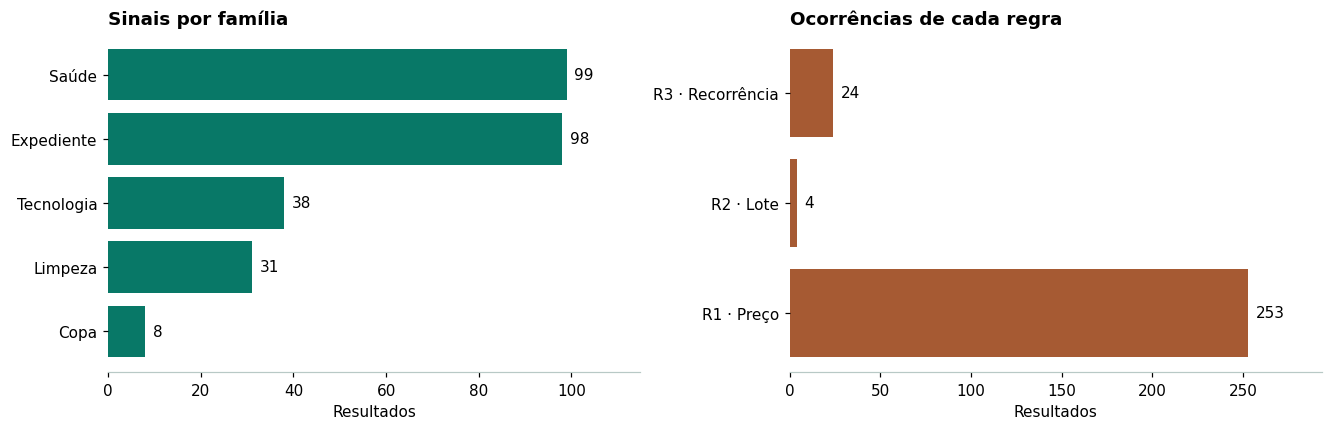

Fila,Material,UF,Item,Regras,Observado,Referência,Exposição
1.0,Papel A4 branco 75 g/m²,BA,7823110690008202500001,R1 + R2,"R$ 13.399,20","R$ 23,27","R$ 13.375,94"
2.0,Papel A4 branco 75 g/m²,RJ,9309210690011202500001,R1 + R2,"R$ 8.850,00","R$ 23,27","R$ 8.826,74"
3.0,Papel A4 branco 75 g/m²,AM,9268490690009202500001,R1 + R2,"R$ 8.700,00","R$ 23,27","R$ 8.676,74"
4.0,Papel A4 branco 75 g/m²,RN,9267070690002202500002,R1 + R2,"R$ 5.975,00","R$ 23,27","R$ 5.951,74"
5.0,"Água sanitária 2–2,5%",SP,9264950590130202400019,R1 + R3,"R$ 3,80","R$ 1,89","R$ 3.056,00"
6.0,Papel A4 branco 75 g/m²,RS,1604370600101202500004,R1 + R3,"R$ 36,90","R$ 23,27","R$ 163,62"
7.0,Dipirona sódica 500 mg,MG,1680050692040202500047,R1 + R3,"R$ 2,00","R$ 0,19","R$ 45,25"
8.0,Dipirona sódica 500 mg,SP,9862910590316202400012,R1,"R$ 9,40","R$ 0,12","R$ 1.252.800,00"


**Ficha do primeiro resultado**

,Informação para conferência
Compra,78231106900082025
Item,7823110690008202500001
UASG,782311
Órgão,COMANDO DA MARINHA
Objeto da compra,"Objeto: AQUISIÇÃO de MATERIAIS DE EXPEDIENTES E COPOS DESCARTÁVEIS DIVIDIDO EM DOIS LOTES. LOTE 01: MATERIAIS DE EXPEDIENTE, LOTE 02: COPOS DESCARTÁVEIS. DE ACORDO COM ITENS DISCRIMINADOS NO AVISO E TERMO DE REFERÊNCIA."
Apresentação,Embalagem de 500 folhas
Quantidade,1.0
Motivos,R1 + R2
Compra anterior,—
Data anterior,—


In [4]:
display(Markdown(f"**{fila.id_compra.nunique()} compras para revisar** · {len(fila)} resultados · "
                 f"{fila.catmat.nunique()} materiais · **{int(fila.prioridade.eq('Alta').sum())} resultados com prioridade alta**"))
if len(fila):
    por_familia=fila.familia.value_counts().sort_values()
    regras=fila[["r1_preco","r2_lote","r3_recorrencia"]].sum()
    fig,(a,b)=plt.subplots(1,2,layout="constrained")
    for ax,serie,labels,titulo,cor in [(a,por_familia,por_familia.index,"Sinais por família",teal),
                      (b,regras,["R1 · Preço","R2 · Lote","R3 · Recorrência"],"Ocorrências de cada regra",laranja)]:
        barras=ax.barh(labels,serie.values,color=cor)
        ax.bar_label(barras,padding=5)
        ax.set(title=titulo,xlabel="Resultados",xlim=(0,max(1,serie.max())*1.16))
    plt.show()
    amostra=fila.head(8).copy()
    cols=["posicao","material","uf","id_compra_item","regras","preco_unitario","referencia","exposicao"]
    amostra[["preco_unitario","referencia","exposicao"]]=amostra[["preco_unitario","referencia","exposicao"]].apply(lambda c:c.map(moeda))
    amostra=amostra[cols]
    amostra.columns=["Fila","Material","UF","Item","Regras","Observado","Referência","Exposição"]
    display(HTML(amostra.to_html(index=False,escape=True)))
    r=fila.iloc[0]
    display(Markdown("**Ficha do primeiro resultado**"))
    ficha=pd.Series({"Compra":r.id_compra,"Item":r.id_compra_item,"UASG":r.codigo_uasg,"Órgão":r.orgao,
                     "Objeto da compra":r.objeto_compra,"Apresentação":r.apresentacao,"Quantidade":r.quantidade,
                     "Motivos":r.motivos,"Compra anterior":r.compra_anterior,"Data anterior":r.data_anterior})
    display(HTML(ficha.fillna("—").to_frame("Informação para conferência").to_html(escape=True)))
    if str(r.url_fonte).startswith("https://dadosabertos.compras.gov.br/"):
        display(HTML('<a target="_blank" rel="noopener" href="'+html.escape(r.url_fonte,quote=True)+'">Consultar a fonte oficial do preço</a>'))
else:
    print("Sem resultados para revisão neste recorte.")

## Cobertura

O denominador inclui todos os resultados de 2025 dos códigos selecionados. O histórico mínimo de 20 observações na mesma coorte evita produzir uma referência numérica sem suporte suficiente. O gráfico separa resultados comparáveis de pendências para cada material.

**2426 resultados** · 2146 comparáveis · 280 pendentes · 1867 compras distintas

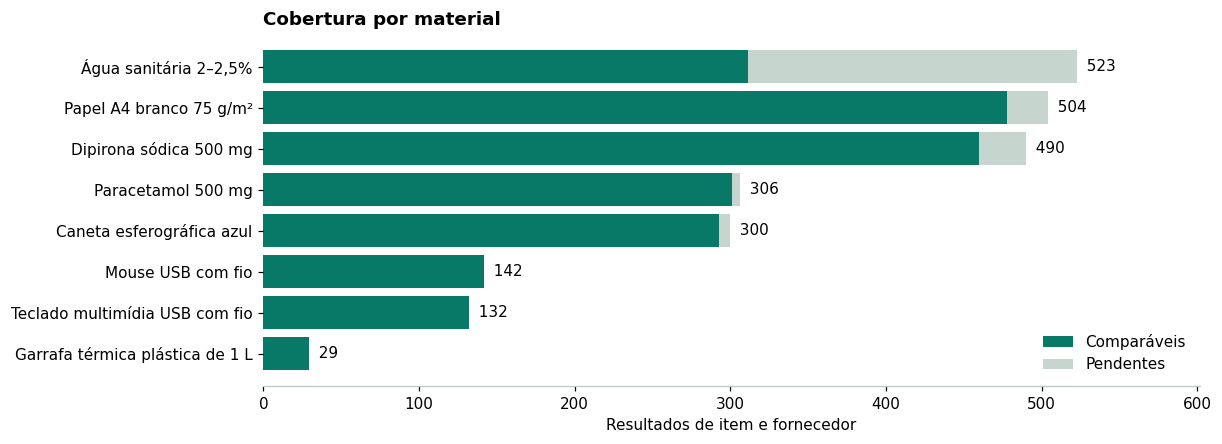

,Resultados
status,
Comparável,2146
Apresentação fora do recorte,275
Histórico insuficiente,5


In [5]:
comparaveis=recorte.status.eq("Comparável")
display(Markdown(f"**{len(recorte)} resultados** · {int(comparaveis.sum())} comparáveis · "
                 f"{int((~comparaveis).sum())} pendentes · {recorte.id_compra.nunique()} compras distintas"))
if len(recorte):
    grupos=(recorte.assign(Comparaveis=comparaveis.astype(int),Pendentes=(~comparaveis).astype(int))
            .groupby("material")[["Comparaveis","Pendentes"]].sum())
    grupos=grupos.loc[grupos.sum(axis=1).sort_values().index]
    fig,ax=plt.subplots(figsize=(11,max(3,.49*len(grupos))),layout="constrained")
    ax.barh(grupos.index,grupos.Comparaveis,color=teal,label="Comparáveis")
    ax.barh(grupos.index,grupos.Pendentes,left=grupos.Comparaveis,color=cinza,label="Pendentes")
    for i,t in enumerate(grupos.sum(axis=1)):
        ax.text(t,i,"  "+str(t),va="center")
    ax.set(title="Cobertura por material",xlabel="Resultados de item e fornecedor",xlim=(0,grupos.sum(axis=1).max()*1.15))
    ax.legend(frameon=False,loc="lower right")
    plt.show()
    c=recorte.groupby("status").size().sort_values(ascending=False).rename("Resultados").to_frame()
    display(HTML(c.to_html()))
else:
    print("Sem registros no recorte.")

## Validação temporal e previsão

Cada coorte combina CATMAT e apresentação. No histórico de 2024, os tercis da quantidade geram faixas de volume baixo, médio e alto. O modelo usa a mediana de preço da faixa, com retorno à mediana da coorte quando a faixa tem menos de dez registros. O teste de 2025 exclui compras presentes no treino.

A referência simples aplica a mediana de 2024 da mesma coorte a todas as quantidades. MAE é a média do erro absoluto. A apresentação e a escala de preços variam entre produtos, por isso a tabela compara os métodos por coorte.

Calibração em 11 coortes de 2024. Teste em 2146 resultados de 2025.
MAE do modelo · R$ 94,41
MAE da referência · R$ 94,54
Erro percentual absoluto mediano · 17,93%


Material,Apresentação,Resultados,Modelo,Referência
Caneta esferográfica azul,Caixa de 50 unidades,119,"R$ 5,22","R$ 6,40"
Caneta esferográfica azul,Unidade,174,"R$ 2,76","R$ 2,81"
Dipirona sódica 500 mg,Comprimido,460,"R$ 0,91","R$ 0,91"
Garrafa térmica plástica de 1 L,Unidade,29,"R$ 4,46","R$ 4,40"
Mouse USB com fio,Unidade,142,"R$ 119,14","R$ 118,97"
Papel A4 branco 75 g/m²,Embalagem de 100 folhas,24,"R$ 2,95","R$ 2,95"
Papel A4 branco 75 g/m²,Embalagem de 500 folhas,454,"R$ 102,50","R$ 102,78"
Paracetamol 500 mg,Comprimido,301,"R$ 446,57","R$ 446,57"
Teclado multimídia USB com fio,Unidade,132,"R$ 19,92","R$ 19,99"
"Água sanitária 2–2,5%",Frasco de 1 litro,148,"R$ 0,62","R$ 0,65"


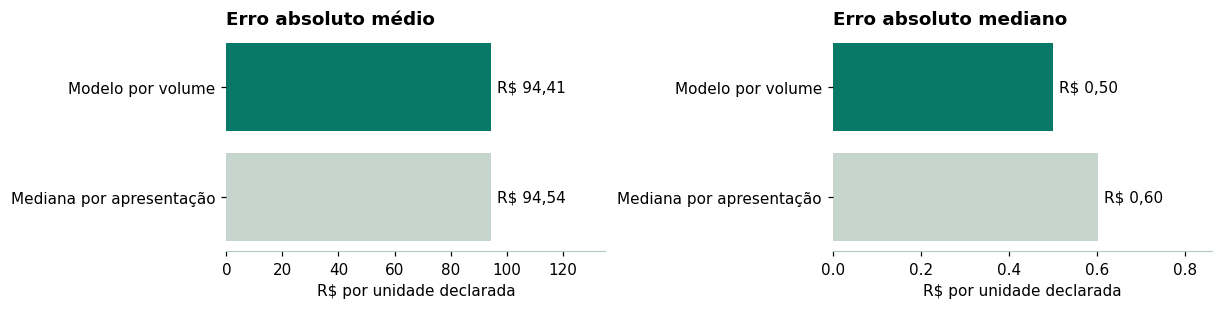

In [6]:
def tercis(valores):
    # A posição tem denominador 3. divmod preserva a igualdade quando o corte coincide com um lote inteiro.
    from fractions import Fraction
    ordenados=sorted(Fraction(str(v)) for v in valores)
    n=len(ordenados)
    cortes=[]
    for k in (1,2):
        i,resto=divmod((n-1)*k,3)
        a,b=ordenados[i],ordenados[min(i+1,n-1)]
        cortes.append(float(a+(b-a)*resto/3))
    return cortes

def treinar(df):
    modelos={}
    for chave_coorte,g in df.groupby(coorte):
        if len(g)<20:
            continue
        cortes=tercis(g.quantidade)
        classes=np.where(g.quantidade<=cortes[0],0,np.where(g.quantidade<=cortes[1],1,2))
        global_=g.preco_unitario.median()
        referencias=[]
        for i in range(3):
            fatia=g.loc[classes==i,"preco_unitario"]
            referencias.append(fatia.median() if len(fatia)>=10 else global_)
        modelos[chave_coorte]={"n":len(g),"cortes":cortes,"referencias":referencias,"baseline":global_}
    return modelos

def predizer(modelo,quantidade):
    c1,c2=modelo["cortes"]
    pos=0 if quantidade<=c1 else 1 if quantidade<=c2 else 2
    return modelo["referencias"][pos]

modelos=treinar(treino.loc[treino.status.eq("Elegível")])
validacao=base.loc[base.valida_teste.eq(1)].copy()
assert len(validacao)>0
compras_de_treino=set(treino.loc[
    treino.status.eq("Elegível") & treino[coorte].apply(tuple,axis=1).isin(modelos),"id_compra"])
assert not compras_de_treino.intersection(validacao.id_compra)
estimadas=[predizer(modelos[(r.catmat,r.apresentacao)],r.quantidade) for r in validacao.itertuples()]
medianas=[modelos[(r.catmat,r.apresentacao)]["baseline"] for r in validacao.itertuples()]
np.testing.assert_allclose(estimadas,validacao.referencia)
np.testing.assert_allclose(medianas,validacao.baseline)
validacao["erro_calculado"]=abs(validacao.preco_unitario-np.array(estimadas))
validacao["erro_base_calculado"]=abs(validacao.preco_unitario-np.array(medianas))
np.testing.assert_allclose(validacao.erro_calculado,validacao.erro_modelo)
np.testing.assert_allclose(validacao.erro_base_calculado,validacao.erro_baseline)
for metodo,col in [("modelo","erro_calculado"),("baseline","erro_base_calculado")]:
    assert np.isclose(validacao[col].mean(),oficial["avaliacao"]["mae_"+metodo])
vt=selecionar(validacao)
resumo = f"Calibração em {len(modelos)} coortes de 2024. Teste em {len(validacao)} resultados de 2025."
if len(vt) != len(validacao):
    resumo += f" O recorte selecionado contém {len(vt)} resultados."
print(resumo)
if len(vt):
    modelo=vt.erro_calculado.mean()
    referencia=vt.erro_base_calculado.mean()
    ape=(vt.erro_calculado/vt.preco_unitario).median()*100
    percentual = f"{ape:.2f}%".replace(".", ",")
    print(f"MAE do modelo · {moeda(modelo)}")
    print(f"MAE da referência · {moeda(referencia)}")
    print(f"Erro percentual absoluto mediano · {percentual}")
    m=vt.groupby(["material","apresentacao"]).agg(Resultados=("id_compra_item","size"),
                   Modelo=("erro_calculado","mean"),Referência=("erro_base_calculado","mean"))
    m[["Modelo","Referência"]]=m[["Modelo","Referência"]].apply(lambda col:col.map(moeda))
    m = m.rename_axis(["Material", "Apresentação"]).reset_index()
    display(HTML(m.to_html(index=False, escape=True)))
    met={"Erro absoluto médio":[modelo,referencia],"Erro absoluto mediano":[vt.erro_calculado.median(),vt.erro_base_calculado.median()]}
    fig,axes=plt.subplots(1,2,figsize=(11,2.7),layout="constrained")
    for ax,(nome,valores) in zip(axes,met.items()):
        barras=ax.barh(["Modelo por volume","Mediana por apresentação"],valores,color=[teal,cinza])
        ax.bar_label(barras,labels=[moeda(x) for x in valores],padding=4)
        ax.set(title=nome,xlabel="R$ por unidade declarada",xlim=(0,max(max(valores),.01)*1.43))
        ax.invert_yaxis()
    plt.show()
else:
    print("O recorte selecionado não contém registros elegíveis para o teste.")

### Simulação de planejamento

A simulação refaz os tercis e as medianas com os resultados elegíveis de 2025. Ela estima um preço de referência como se o planejamento ocorresse em 1º de janeiro de 2026. O exemplo inicial usa 30 teclados USB. Para outros cenários, altere o código e a apresentação para um par listado no resultado da célula ou use o seletor do painel.

In [7]:
CATMAT = "451819" #@param {type:"string"}
APRESENTACAO = "Unidade" #@param {type:"string"}
QUANTIDADE = 30 #@param {type:"integer"}

# O status de 2025 também registra falta de histórico em 2024. Para a nova calibração,
# as coortes válidas são as que a transformação classificou como elegíveis neste ano.
habilitados={(str(m["catmat"]),m["apresentacao"])
             for m in oficial["modelos_2025"] if m.get("habilitado",True)}
aceitos=base.loc[base[coorte].apply(tuple,axis=1).isin(habilitados) &
                 base.status.isin(["Comparável","Histórico insuficiente"])]
recalibrados=treinar(aceitos)
print("Opções de CATMAT e apresentação")
for m in oficial["modelos_2025"]:
    if m.get("habilitado",True):
        print(f"  {m['catmat']} · {m['material']} · {m['apresentacao']}")
if not isinstance(QUANTIDADE,int) or QUANTIDADE<1:
    raise ValueError("Informe uma quantidade inteira positiva.")
escolhida=(CATMAT.strip(),APRESENTACAO.strip())
if escolhida not in recalibrados:
    raise ValueError("Selecione uma das combinações de código e apresentação listadas acima.")
modelo=recalibrados[escolhida]
v=predizer(modelo,QUANTIDADE)
publicado=next(m for m in oficial["modelos_2025"]
               if str(m["catmat"])==escolhida[0] and m["apresentacao"]==escolhida[1])
assert modelo["n"]==publicado["n"]
np.testing.assert_allclose(modelo["referencias"],[g["referencia"] for g in publicado["faixas"]])
print(f"{QUANTIDADE} × {publicado['material']} · {APRESENTACAO}")
print(f"{moeda(v)} por unidade · {moeda(v * QUANTIDADE)} para o lote")
print(f"Calibração com {modelo['n']} resultados da coorte em 2025.")

Opções de CATMAT e apresentação
  461889 · Papel A4 branco 75 g/m² · Embalagem de 500 folhas
  461889 · Papel A4 branco 75 g/m² · Embalagem de 100 folhas
  462546 · Caneta esferográfica azul · Unidade
  462546 · Caneta esferográfica azul · Caixa de 50 unidades
  267778 · Paracetamol 500 mg · Comprimido
  267203 · Dipirona sódica 500 mg · Comprimido
  451819 · Teclado multimídia USB com fio · Unidade
  462261 · Mouse USB com fio · Unidade
  232589 · Garrafa térmica plástica de 1 L · Unidade
  299605 · Água sanitária 2–2,5% · Frasco de 1 litro
  299605 · Água sanitária 2–2,5% · Garrafa de 5 litros
30 × Teclado multimídia USB com fio · Unidade
R$ 25,52 por unidade · R$ 765,60 para o lote
Calibração com 132 resultados da coorte em 2025.


## Painel interativo

Abra um item para conferir o motivo da seleção e a fonte. No Jupyter local, marque o notebook como confiável para habilitar os filtros na visualização abaixo.

In [8]:
pagina=(projeto/"index.html").read_text(encoding="utf-8")
moldura=('<iframe title="Triagem de compras públicas" '
             'sandbox="allow-scripts allow-downloads allow-popups" '
             'style="border:1px solid #cbd9d3;width:100%;height:990px" '
             'srcdoc="'+html.escape(pagina,quote=True)+'"></iframe>')
display({'text/html':moldura,'text/plain':'Painel interativo de triagem de compras públicas'},raw=True)

Painel interativo de triagem de compras públicas